### Импорты

In [1]:
import sys
sys.path.append('../src')

import torch
import pandas as pd
import numpy as np
from pathlib import Path
import importlib
import train as train_module
importlib.reload(train_module)

from dataset import build_item_vocab, build_user_sequences
from metrics import build_eval_targets, build_context
from train import train

PROC = Path('../data/processed')
RESULTS = Path('../results')

train_df = pd.read_parquet(PROC / 'train.parquet')
val_df = pd.read_parquet(PROC / 'val.parquet')

item2idx, idx2item = build_item_vocab(train_df)
vocab_size = len(item2idx) + 2
print(f"Vocab size: {vocab_size}")

Vocab size: 14937


### Данные с фиксами

In [2]:
# FIX: kind='stable'
train_df_sorted = train_df.sort_values(['user_id', 'last_watch_dt'], kind='stable')
train_seqs = {}
for user_id, group in train_df_sorted.groupby('user_id', sort=False):
    items = group['item_id'].tolist()
    train_seqs[user_id] = items[-50:]

# FIX: val-контекст = train + val (полная история)
# Валидация идёт по NDCG@10 на val_targets, но с контекстом из train
val_targets = build_eval_targets(val_df)
val_context = build_context(train_df)

print(f"Train users: {len(train_seqs):,}")
print(f"Val targets: {len(val_targets):,}")

Train users: 727,645
Val targets: 176,224


### Обучение с early stopping по NDCG@10

In [3]:
history_v2 = train(
    train_sequences=train_seqs,
    val_sequences={},  # теперь не используется val_sequences для loss
    item2idx=item2idx,
    vocab_size=vocab_size,
    batch_size=256,
    n_epochs=5,           # больше эпох
    lr=1e-3,
    save_dir=str(RESULTS / 'checkpoints_v2'),
    patience=2,           # early stopping
    seed=42,
    val_targets=val_targets,
    val_context=val_context,
    idx2item=idx2item,
    early_stop_metric='ndcg',  # по метрике, а не по loss
)

Устройство: cuda


[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 14936), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 14936), got 50256. This may result in unexpected behavior.


Train examples: 451,120
Val examples:   0
Train batches/epoch: 1,762
Early stop metric: ndcg

Начало обучение: 5 эпох, batch=256, lr=0.001
Warmup: 881 шагов из 8810

--- Эпоха 1/5 ---


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


    batch 200: loss = 7.2921
    batch 400: loss = 6.9833
    batch 600: loss = 6.7111
    batch 800: loss = 6.6816
    batch 1000: loss = 6.3943
    batch 1200: loss = 6.6108
    batch 1400: loss = 6.4089
    batch 1600: loss = 6.5021
  Считаем NDCG@10 на val...
Уникальных юзеров для оценки: 118,727


...

  train_loss = 6.2474
  val_NDCG@10 = 0.1306
  lr         = 4.13e-04
  время      = 1132.3 сек

  Новый best ndcg: 0.1306

--- Эпоха 4/5 ---
    batch 200: loss = 6.1567
    batch 400: loss = 6.3244
    batch 600: loss = 6.2163
    batch 800: loss = 6.1511
    batch 1000: loss = 6.1855
    batch 1200: loss = 6.0797
    batch 1400: loss = 6.0764
    batch 1600: loss = 6.1103
  Считаем NDCG@10 на val...
Уникальных юзеров для оценки: 118,727


predict_batch:   0%|          | 0/232 [00:00<?, ?it/s]

  train_loss = 6.1968
  val_NDCG@10 = 0.1333
  lr         = 1.17e-04
  время      = 1141.6 сек

  Новый best ndcg: 0.1333

--- Эпоха 5/5 ---
    batch 200: loss = 6.1318
    batch 400: loss = 6.0876
    batch 600: loss = 6.2277
    batch 800: loss = 6.2432
    batch 1000: loss = 5.9796
    batch 1200: loss = 6.2174
    batch 1400: loss = 6.3309
    batch 1600: loss = 6.1238
  Считаем NDCG@10 на val...
Уникальных юзеров для оценки: 118,727


predict_batch:   0%|          | 0/232 [00:00<?, ?it/s]

  train_loss = 6.1663
  val_NDCG@10 = 0.1342
  lr         = 0.00e+00
  время      = 1145.5 сек

  Новый best ndcg: 0.1342


Обучение завершено. Лучший val NDCG@10: 0.1342
Чекпоинты сохранены в: ..\results\checkpoints_v2


### Визуализация, лучшая эпоха

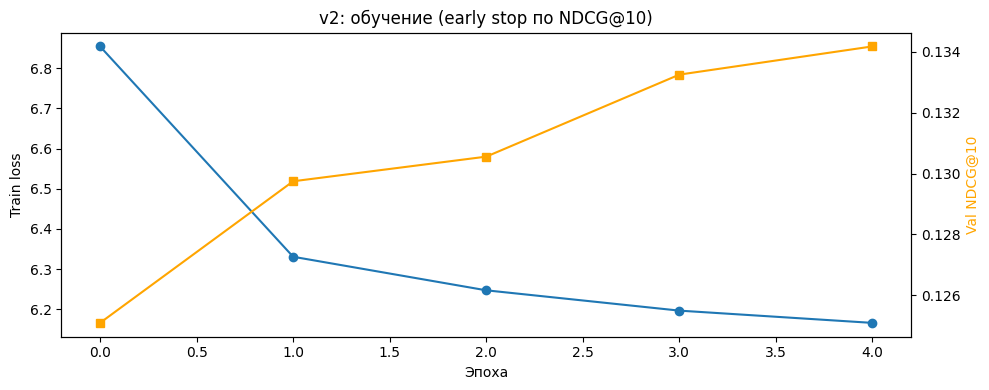

Лучший val NDCG@10: 0.1342


In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history_v2['train_loss'], marker='o', label='Train loss')
if 'val_ndcg' in history_v2:
    ax2 = ax.twinx()
    ax2.plot(history_v2['val_ndcg'], marker='s', color='orange', label='Val NDCG@10')
    ax2.set_ylabel('Val NDCG@10', color='orange')
ax.set_xlabel('Эпоха')
ax.set_ylabel('Train loss')
ax.set_title('v2: обучение (early stop по NDCG@10)')
plt.tight_layout()
plt.show()

# История уже сохраняет best_model.pt — это будет лучшая эпоха по NDCG
print(f"Лучший val NDCG@10: {max(history_v2['val_ndcg']):.4f}")

### Оценка v2 на test

In [5]:
from model import create_model
from my_evaluate import GPT2Predictor, evaluate_gpt2_fast
from metrics import recall_at_k, ndcg_at_k, average_precision_at_k

# Загрузка v2
model_v2 = create_model(vocab_size=vocab_size)
state = torch.load(RESULTS / 'checkpoints_v2' / 'best_model.pt', map_location='cpu')
model_v2.load_state_dict(state)

# Таргеты и контексты для test
test_df = pd.read_parquet(PROC / 'test.parquet')
test_targets = build_eval_targets(test_df)
test_context = build_context(train_df, val_df)

predictor_v2 = GPT2Predictor(model_v2, item2idx, idx2item, max_len=50)
test_preds_v2 = evaluate_gpt2_fast(
    predictor_v2, test_targets, test_context, k=100, batch_size=512, exclude_seen=True
)

def compute_metrics(preds_dict, targets_df, k_values=(10, 50, 100)):
    max_k = max(k_values)
    accum = {f'{m}@{k}': [] for k in k_values for m in ['Recall', 'NDCG', 'MAP']}
    for _, row in targets_df.iterrows():
        preds = preds_dict.get(row['user_id'], [])[:max_k]
        target = row['item_id']
        for k in k_values:
            accum[f'Recall@{k}'].append(recall_at_k(preds, target, k))
            accum[f'NDCG@{k}'].append(ndcg_at_k(preds, target, k))
            accum[f'MAP@{k}'].append(average_precision_at_k(preds, target, k))
    return {k: float(np.mean(v)) for k, v in accum.items()}

gpt2_v2 = compute_metrics(test_preds_v2, test_targets)
print("\nGPT-2 v2 на test (с маскировкой):")
for k, v in gpt2_v2.items():
    print(f"  {k:>12s}: {v:.4f}")

Уникальных юзеров для оценки: 132,323


predict_batch:   0%|          | 0/259 [00:00<?, ?it/s]


GPT-2 v2 на test (с маскировкой):
     Recall@10: 0.2192
       NDCG@10: 0.1304
        MAP@10: 0.1030
     Recall@50: 0.3714
       NDCG@50: 0.1638
        MAP@50: 0.1101
    Recall@100: 0.4592
      NDCG@100: 0.1780
       MAP@100: 0.1113


### Сравнение v1 и v2

In [6]:
# Загрузка v1
model_v1 = create_model(vocab_size=vocab_size)
state_v1 = torch.load(RESULTS / 'checkpoints' / 'best_model.pt', map_location='cpu')
model_v1.load_state_dict(state_v1)

predictor_v1 = GPT2Predictor(model_v1, item2idx, idx2item, max_len=50)
test_preds_v1 = evaluate_gpt2_fast(
    predictor_v1, test_targets, test_context, k=100, batch_size=512, exclude_seen=True
)
gpt2_v1 = compute_metrics(test_preds_v1, test_targets)

# Сравнение
print("=" * 60)
print(f"{'Metric':<15} {'v1':>10} {'v2':>10} {'Δ':>10}")
print("=" * 60)
for m in gpt2_v1:
    delta = (gpt2_v2[m] / gpt2_v1[m] - 1) * 100 if gpt2_v1[m] > 0 else 0
    marker = "+" if delta > 0.5 else ("-" if delta < -0.5 else "~")
    print(f"{m:<15} {gpt2_v1[m]:>10.4f} {gpt2_v2[m]:>10.4f} {delta:>+9.1f}% {marker}")

# Сохранение результаты v2
import pandas as pd
baselines_v3 = pd.read_csv(RESULTS / 'baselines_v3_masked.csv', index_col=0)
final_v3 = baselines_v3.copy()
final_v3['GPT-2 v1'] = pd.Series(gpt2_v1)
final_v3['GPT-2 v2'] = pd.Series(gpt2_v2)
print("\n" + final_v3.round(4).to_string())
final_v3.to_csv(RESULTS / 'final_v3_with_v2.csv')

Уникальных юзеров для оценки: 132,323


predict_batch:   0%|          | 0/259 [00:00<?, ?it/s]

Metric                  v1         v2          Δ
Recall@10           0.2175     0.2192      +0.8% +
NDCG@10             0.1292     0.1304      +0.9% +
MAP@10              0.1020     0.1030      +1.0% +
Recall@50           0.3699     0.3714      +0.4% ~
NDCG@50             0.1625     0.1638      +0.8% +
MAP@50              0.1090     0.1101      +1.0% +
Recall@100          0.4557     0.4592      +0.8% +
NDCG@100            0.1764     0.1780      +0.9% +
MAP@100             0.1102     0.1113      +1.0% +

            Popularity  Recent-Popularity  Pure Last-Item  Item-kNN  GPT-2 v1  GPT-2 v2
Recall@10       0.1726             0.2230             0.0    0.1842    0.2175    0.2192
NDCG@10         0.1032             0.1229             0.0    0.1091    0.1292    0.1304
MAP@10          0.0814             0.0923             0.0    0.0859    0.1020    0.1030
Recall@50       0.2871             0.3436             0.0    0.3402    0.3699    0.3714
NDCG@50         0.1279             0.1498          